<img src="https://raw.githubusercontent.com/GSansigolo/fweather/main/docs/img/fweather.png" align="right" width="200"/>

# <span style="color:#336699">Introduction to the FWeather</span>
<hr style="border:2px solid #0077b9;">

<div style="text-align: left;">
    <a href="https://nbviewer.jupyter.org/github/brazil-data-cube/code-gallery/"><img src="https://raw.githubusercontent.com/jupyter/design/master/logos/Badges/nbviewer_badge.svg" align="center"/></a>
</div>

<br/>

<div style="text-align: center;font-size: 90%;">
    Gabriel Sansigolo<sup><a href="https://orcid.org/0000-0003-0789-5858"><i class="fab fa-lg fa-orcid" style="color: #a6ce39"></i></a></sup>
    <br/><br/>
    Earth Observation and Geoinformatics Division, National Institute for Space Research (INPE)
    <br/>
    Avenida dos Astronautas, 1758, Jardim da Granja, São José dos Campos, SP 12227-010, Brazil
    <br/><br/>
    Contact: <a href="mailto:gabriel.sansigolo@inpe.br">gabriel.sansigolo@inpe.br</a>
    <br/><br/>
    Last Update: Feb 24, 2026
</div>

<br/>

<div style="text-align: justify;  margin-left: 25%; margin-right: 25%;">
<b>Abstract.</b> This Jupyter Notebook gives an overview on how to use the FWeather to create creating <em>multidimensional arrays</em> from satellite imagery.
</div>

<br/>
<div style="text-align: justify;  margin-left: 25%; margin-right: 25%;font-size: 75%; border-style: solid; border-color: #0077b9; border-width: 1px; padding: 5px;">
    <b>This Jupyter Notebook is a supplement to the following paper:</b>
    <div style="margin-left: 10px; margin-right: 10px">
    Sansigolo, G.; Ferreira, K. R.; Queiroz, G. R.; Giarolla, A.; Adami, M.<a href="http://www.google.com" target="_blank">Meteorological Time Series Analysis from Big Earth Observation Data
    </div>
</div>

# Introduction
<hr style="border:1px solid #0077b9;">

The **fweather** is an open-source Python package for meteorological time series analysis. It used the SpatioTemporal Asset Catalog (STAC) to access meteorological data and retrieve it as virtual data cubes, facilitating the retrieval of time series. 

It provides methods of building a data cube and retrieving time series of cumulative precipitation, daily precipitation, temperature and climate change projections. 

With the package, it’s possible to perform large-scale agriculture monitoring using weather time series with no need to download data locally and programming skills. The proposed tool was developed as a component of the Brazil Data Cube (BDC) platform. 

FWeather client features two main functions: 

- ``data_cube()``: Function that allow the researcher to define the desired data cube, with it the fweather build a virtual data cube of precipitation, temperature, or climate change projection data for the desired region.

- ``get_timeseries()``: Function that works by allowing the researcher to extract meteorological time series for a point (latitude and longitude).

This Jupyter Notebook shows how to use smosaics in Python with Brazil Data Cube data.

## Operations
<hr style="border:1px solid #0077b9;">

The ``data_cube()`` and ``get_timeseries()`` functions of the fweather package follow the same workflow, illustrated by the cascade structure on the right side (Figure 1).

<div align="center">
    <figcaption><strong>Figure 1</strong> - Workflow of the meteorological time series analyses tool. </figcaption>
    <img src="https://i.ibb.co/v64dXVNp/fweather-full.png" align="center" width="768"/>
    <br>
</div>

Module (a), the Python client component, includes layers for schema the data cube, discovery the data from the collection, access the data set and stacking the data set into a data cube. The outputs of this client are xarray of the meteorological data and JSON file of the meteorological time series.

# fweather package
<hr style="border:1px solid #0077b9;">

For running the examples in this Jupyter Notebook you will need to install the [fweather python package](https://github.com/GSansigolo/fweather). To install it from PyPI using `pip`, use the following command:

In [1]:
#!pip install fweather

In order to access the funcionalities of the package, you should import the `fweather` package, as follows:

In [2]:
from fweather import data_cube

After that, you should create a `stac_url` python variable attached to a given service:

In [3]:
stac_url = "https://data.inpe.br/bdc/stac/v1"

# Creating a precipitation data cube based on MERGE Daily data
<hr style="border:1px solid #0077b9;">

To creating a precipitation data cube based on MERGE Daily data from `January 1st, 2024` to `December 31st, 2024`, use the `data_cube()` function. Set the `collection` parameter to `prec_merge_daily-1` to the retrive the MERGE Daily data from BIG catalog, and the `bands` to `merge_daily`.

In [4]:
prec_merge_cube=data_cube(
    stac_url=stac_url,
    collection="prec_merge_daily-1",
    start_date="2024-01-01",
    end_date="2024-12-31",
    bbox="-47.2797,-17.0725,-45.4779,-15.4485",
    bands=["merge_daily"]
)

prec_merge_cube

Fetching... : 100%|██████████| 366/366 [01:47<00:00,  3.40 scenes/s]


<xarray.Dataset> Size: 451kB
Dimensions:    (latitude: 17, longitude: 18, time: 366)
Coordinates:
  * latitude   (latitude) float64 136B -17.05 -16.95 -16.85 ... -15.55 -15.45
  * longitude  (longitude) float64 144B 312.8 312.9 313.0 ... 314.3 314.4 314.5
  * time       (time) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-31
Data variables:
    rdp        (time, latitude, longitude) float32 448kB 19.56 20.06 ... 3.25

# Fetching a Time Series from Data Cube
<hr style="border:1px solid #0077b9;">

To recover the time series from a xarray you need to inform the location, the FWeather uses the parameter ``latitude`` and ``longitude`` parameters as Coordinates. They must be passed. See example in the code below: 

In [5]:
ts = {'values': prec_merge_cube['rdp'].sel(latitude=-11.739, longitude=314.247, method='nearest').values, 'timeline': prec_merge_cube['time'].values}

In [6]:
ts['values'][:16]

array([ 4.875 ,  4.9375, 22.5   , 11.625 , 17.875 ,  3.625 ,  4.5   ,
       14.6875,  6.9375,  0.8125,  0.4375,  0.    ,  0.125 ,  4.125 ,
        3.3125,  4.1875], dtype=float32)

# Visualizing the Time Series with Seaborn
<hr style="border:1px solid #0077b9;">

<Axes: xlabel='timeline', ylabel='values'>

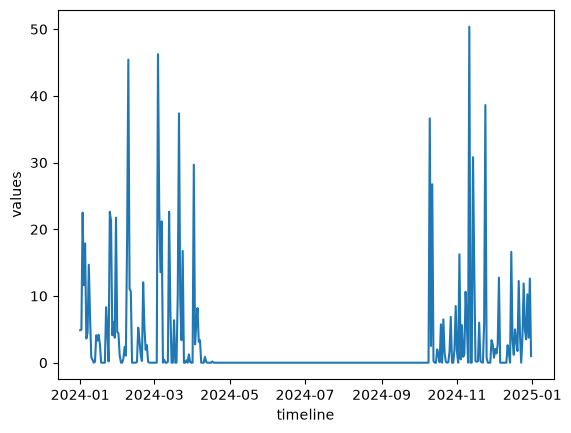

In [8]:
import seaborn as sns
import pandas as pd

df = pd.DataFrame(ts)

df['timeline'] = pd.to_datetime(pd.to_numeric(df['timeline']), unit='ns')

df = df.sort_values('timeline')

sns.lineplot(x='timeline', y='values', data=df)